In [1]:
import numpy as np
import pandas as pd 
import tensorflow as tf 
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model
with tf.device('/CPU:0'):
    # Operations here run on the CPU
    tensor_cpu = tf.constant([4.0, 5.0, 6.0], shape=[1, 3])
    print(f"Tensor on device: {tensor_cpu.device}")

Tensor on device: /job:localhost/replica:0/task:0/device:CPU:0


In [2]:
data = pd.read_csv("power_system_multiclass_anomaly_data.csv")
features = ['Voltage (V)','Current (A)','Power (kW)','Frequency (Hz)','Power_Factor',]
data = data[features]


In [3]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)


In [4]:
def create_sequences(data, time_steps=50):
    sequences = []
    for i in range(len(data) - time_steps):
        sequences.append(data[i:i + time_steps])
    return np.array(sequences)

TIME_STEPS = 50
X = create_sequences(scaled_data, TIME_STEPS)


In [5]:
X_train, X_temp = train_test_split(X, test_size=0.799, shuffle=False)
X_val, X_test = train_test_split(X_temp, test_size=0.4, shuffle=False)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)


Train: (1999, 50, 5)
Validation: (4770, 50, 5)
Test: (3181, 50, 5)


In [6]:
inputs = layers.Input(shape=(TIME_STEPS, X.shape[2]))
encoded = layers.LSTM(2500, return_sequences = True)(inputs)
encoded = layers.LSTM(1250, return_sequences = True)(encoded)
encoded = layers.LSTM(625, return_sequences = True)(encoded)
encoded = layers.LSTM(313, return_sequences = False)(encoded)
latent = layers.Dense(256, activation = "relu")(encoded)
decoded = layers.RepeatVector(TIME_STEPS)(latent)
decoded = layers.LSTM(2500, return_sequences=True)(decoded) 
decoded = layers.LSTM(1250, return_sequences=True)(decoded)
decoded = layers.LSTM(625, return_sequences=True)(decoded)
decoded = layers.LSTM(313, return_sequences=True)(decoded)
outputs = layers.TimeDistributed(layers.Dense(X.shape[2]))(decoded)

model = models.Model(inputs, outputs)
model.compile(optimizer ="adam",loss = "mse")
model.summary()
                      

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 50, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 50, 2500)       │    25,060,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50, 1250)       │    18,755,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 50, 625)        │     4,690,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 313)            │     1,175,628 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        80,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector (RepeatVector)    │ (None, 50, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 50, 2500)       │    27,570,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 50, 1250)       │    18,755,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 50, 625)        │     4,690,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 50, 313)        │     1,175,628 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 50, 5)          │         1,570 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,953,210 (388.92 MB)

 Trainable params: 101,953,210 (388.92 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
History = model.fit(X_train, X_train,
                epochs = 40,
                batch_size = 64,
                validation_data = (X_val, X_val),
                verbose = 1)

Epoch 1/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 368s 11s/step - loss: 0.2955 - val_loss: 0.0194
Epoch 2/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 345s 11s/step - loss: 0.0173 - val_loss: 0.0172
Epoch 3/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 353s 11s/step - loss: 0.0162 - val_loss: 0.0167
Epoch 4/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 355s 11s/step - loss: 0.0159 - val_loss: 0.0165
Epoch 5/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 349s 11s/step - loss: 0.0157 - val_loss: 0.0163
Epoch 6/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 348s 11s/step - loss: 0.0155 - val_loss: 0.0162
Epoch 7/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 348s 11s/step - loss: 0.0154 - val_loss: 0.0162
Epoch 8/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 347s 11s/step - loss: 0.0154 - val_loss: 0.0161
Epoch 9/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 346s 11s/step - loss: 0.0153 - val_loss: 0.0161
Epoch 10/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 348s 11s/step - loss: 0.0153 - val_loss: 0.0161
Epoch 11/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 349s 11s/step - loss: 0.0153 - val_loss: 0.0161
Epoch 12/40
32/32 ━━━━━━━━━━━━━━━━━━━━ 347s 11s/step

In [8]:
train_recon = model.predict(X_train)
train_loss = np.mean(np.abs(train_recon - X_train), axis=(1,2))


63/63 ━━━━━━━━━━━━━━━━━━━━ 77s 1s/step


In [9]:
threshold = np.mean(train_loss) + 3 * np.std(train_loss)
print("Anomaly Threshold:", threshold)


Anomaly Threshold: 0.09948402162116371


In [10]:
test_recon = model.predict(X_test)
test_loss = np.mean(np.abs(test_recon - X_test), axis=(1,2))

anomalies = test_loss > threshold


100/100 ━━━━━━━━━━━━━━━━━━━━ 106s 1s/step


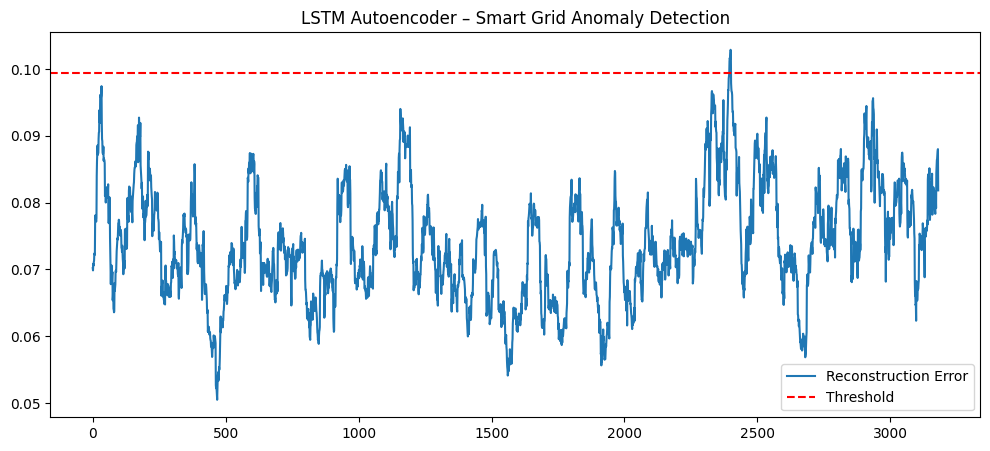

In [11]:
plt.figure(figsize=(12,5))
plt.plot(test_loss, label="Reconstruction Error")
plt.axhline(threshold, color='red', linestyle='--', label="Threshold")
plt.legend()
plt.title("LSTM Autoencoder – Smart Grid Anomaly Detection")
plt.show()


In [12]:
print("Total Test Samples:", len(test_loss))
print("Detected Anomalies:", np.sum(anomalies))


Total Test Samples: 3181
Detected Anomalies: 6


In [14]:
model.save("smart_grid_anomaly_detection.h5")
